<a href="https://colab.research.google.com/github/elisabethandriivna/Portfolio/blob/main/Lab2_Kaprelova.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


Перші 5 рядків датасету:
   Unnamed: 0 Company Name Model Name    Price  Model Year   Location  \
0           0       Toyota       Vitz  2385000        2017  Islamabad   
1           1       Toyota    Corolla   111000        2019        KPK   
2           2       Suzuki       Alto  1530000        2019        KPK   
3           3       Suzuki       Alto  1650000        2019     Punjab   
4           4       Toyota    Corolla  1435000        2010  Islamabad   

   Mileage Engine Type  Engine Capacity   Color  Assembly  Body Type  \
0     9869      Petrol             1000  Silver  Imported  Hatchback   
1    11111      Petrol             1300   White     Local      Sedan   
2    17500      Petrol              660   White     Local  Hatchback   
3     9600      Petrol              660   White     Local  Hatchback   
4   120000      Petrol             1300   Black     Local      Sedan   

  Transmission Type Registration Status  
0         Automatic       Un-Registered  
1         Automati

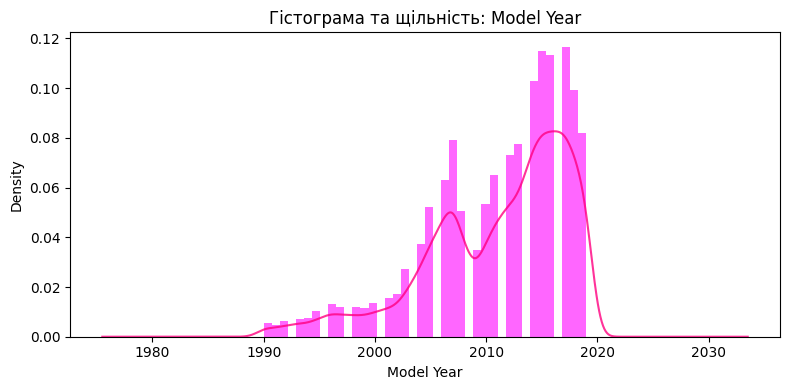

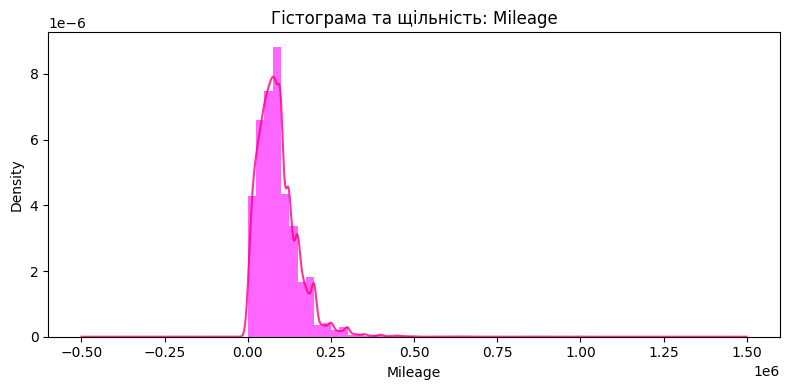

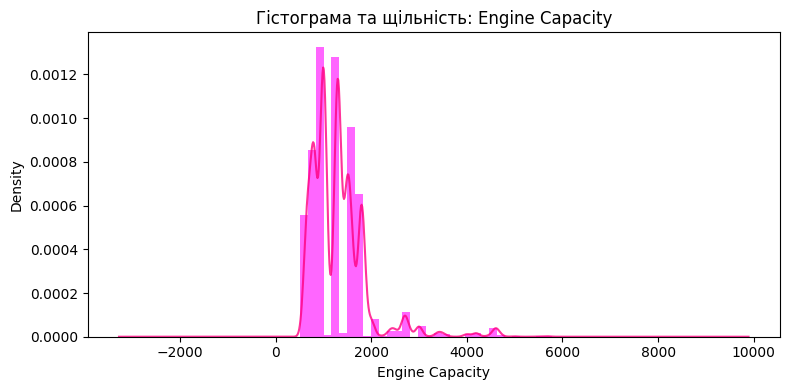

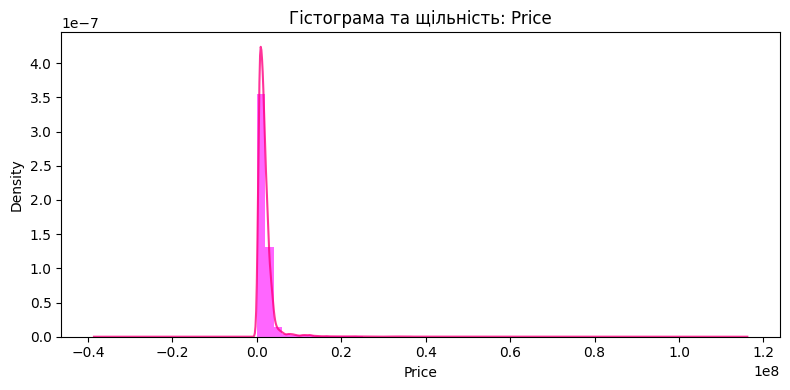

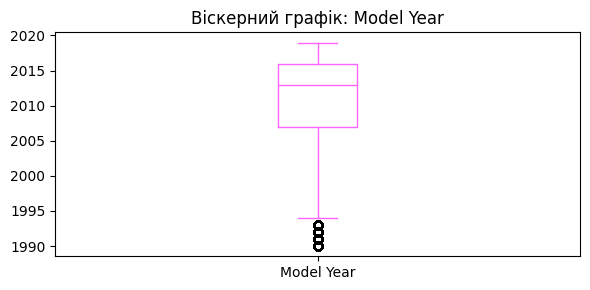

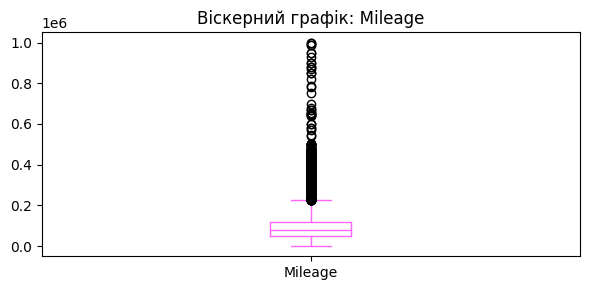

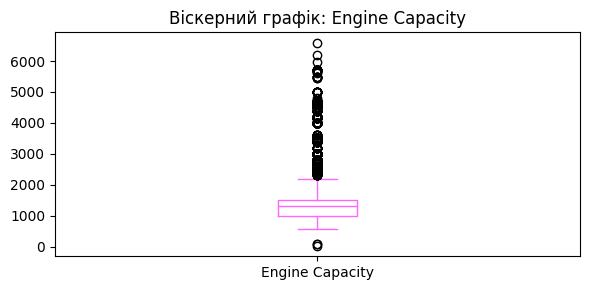

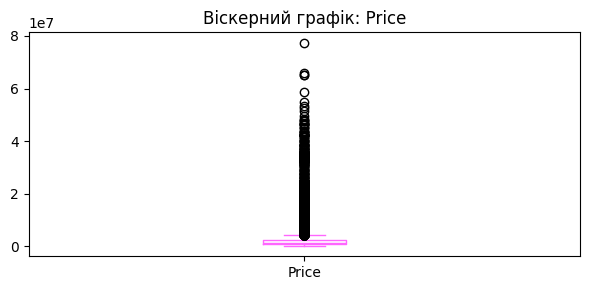

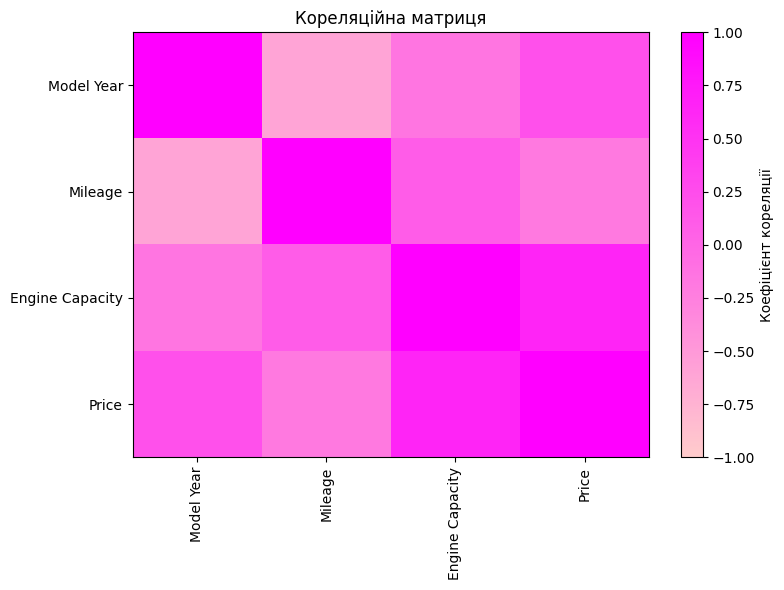

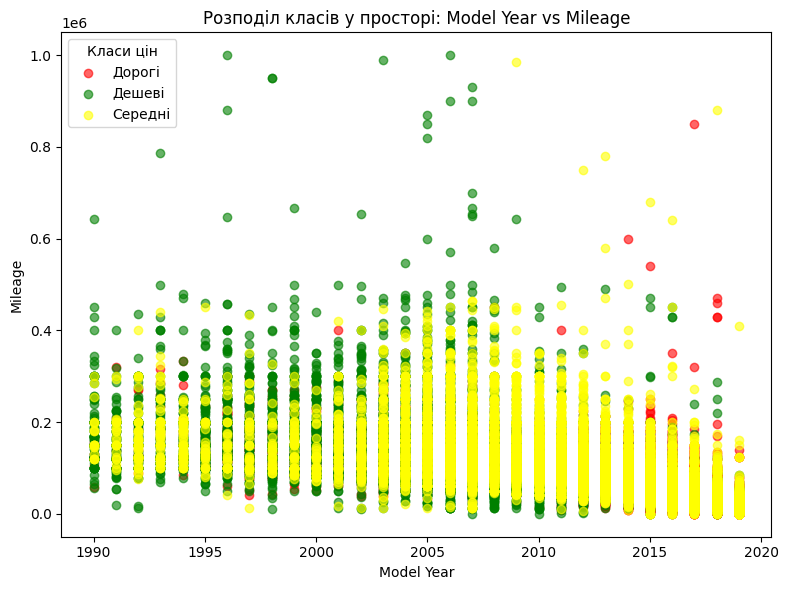

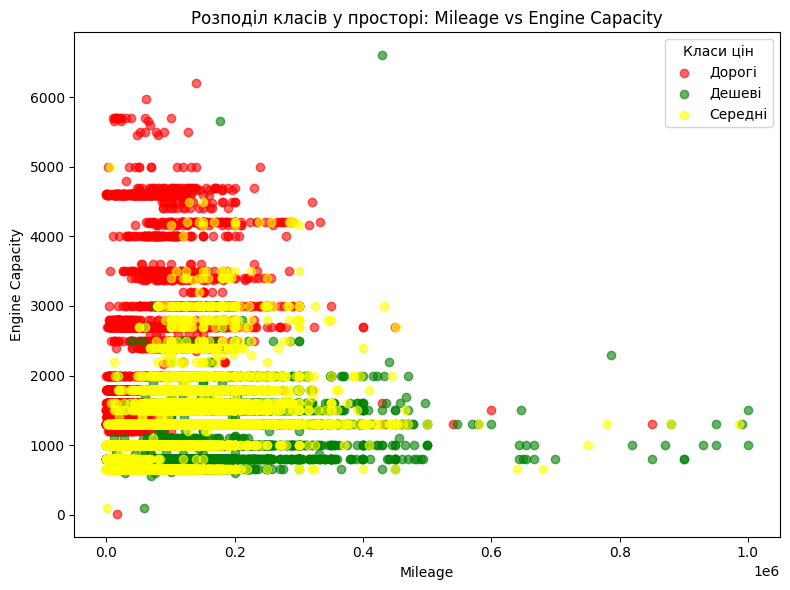

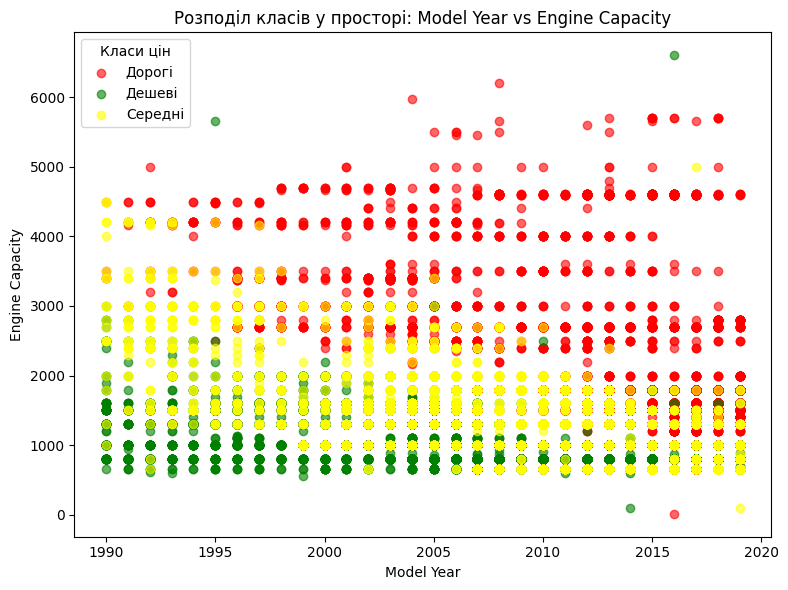

/tmp/ipykernel_428/9251649.py:153: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = plt.boxplot(data_to_plot, labels=df['price_class'].unique(), patch_artist=True)


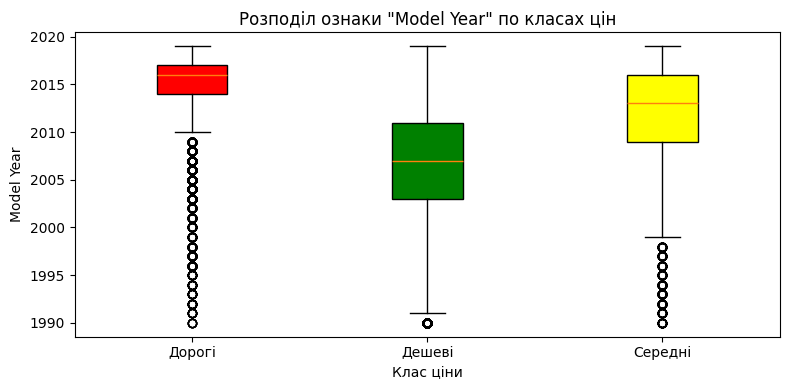

/tmp/ipykernel_428/9251649.py:153: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = plt.boxplot(data_to_plot, labels=df['price_class'].unique(), patch_artist=True)


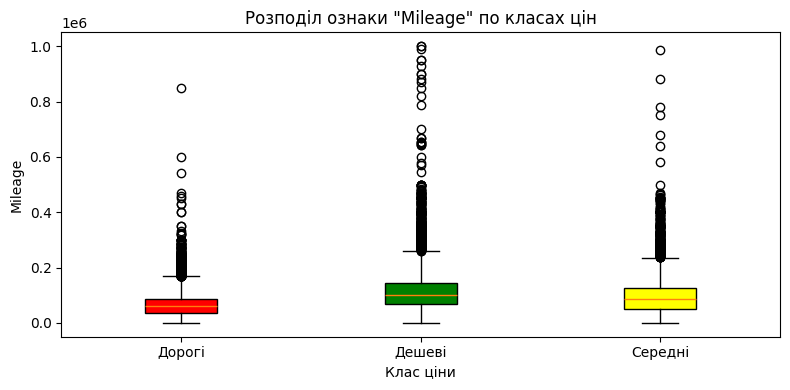

/tmp/ipykernel_428/9251649.py:153: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = plt.boxplot(data_to_plot, labels=df['price_class'].unique(), patch_artist=True)


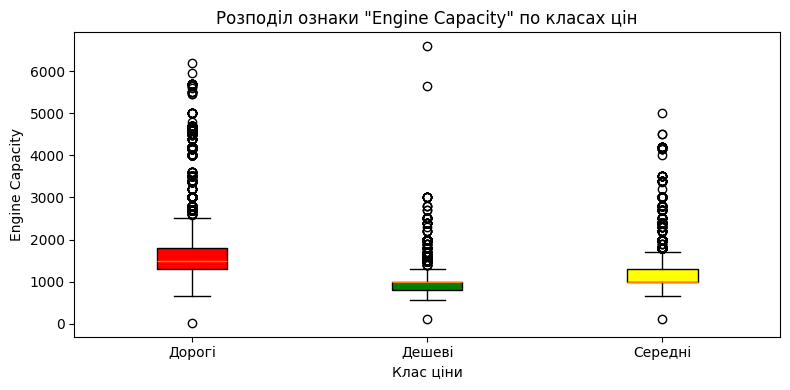


--- Висновки:
1) Для класифікації обрано 3 інтервали цін: Дешеві, Середні, Дорогі.
2) Найбільший коефіцієнт кореляції можна побачити між Price та Engine Capacity (якщо не враховувати кореляцію між самим собою). Найменший між Mileage та Model year
3) Дорогі машини мають високий Engine Capacity, більш високий Model Year і менший Mileage.
4) Дешеві машини мають низький Engine Capacity, меньший Model Year і вищий Mileage.
5) Машини з середньою ціною мають середній Engine Capacity, більш менш високий/середній Model Year і середній Mileage.


In [6]:
!pip install -q kaggle
!pip install -q scikit-learn matplotlib pandas numpy
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import LabelEncoder
from matplotlib.colors import LinearSegmentedColormap
DATA_PATH = 'Clean_Data_pakwheels.csv' # замініть на свій файл
df = pd.read_csv(DATA_PATH)
pd.set_option('display.max_columns', 60)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif

pd.set_option('display.max_columns', 60)
df = pd.read_csv(DATA_PATH)
print('\nПерші 5 рядків датасету:')
print(df.head())
print('\nІнформація про датасет:')
print(df.info())
print('\nОпис числових колонок:')
print(df.describe())

# --- 1) Постановка задачі класифікації ---
#   - поділяємо ціну автомобіля (price) на n_classes категорій (Low / Medium / High).
#   - мета: за технічними характеристиками авто (Model Year, Mileage, Engine Capacity) визначити,
#     до якої цінової категорії воно належить.

if 'price' in df.columns:
   price_col = 'Price'
else:
 possible_price_cols = [c for c in df.columns if 'price' in c.lower()]
 if len(possible_price_cols) > 0:
  price_col = possible_price_cols[0]
 else:
  raise ValueError('Не знайдено колонки з ціною. Перевірте файл і вкажіть колонку вручну.')

n_classes = 3
df['price_class'] = pd.qcut(df[price_col], q=n_classes, labels=['Дешеві', 'Середні', 'Дорогі'])
print('\nРозподіл класів по кількості:')
print(df['price_class'].value_counts())

# --- 2) Аналіз інформативності ознак ---
num_cols = ['Model Year', 'Mileage', 'Engine Capacity', 'Price'] # лише потрібні ознаки
print("\nОбрані числові колонки для аналізу:", num_cols)

# Заповнення пропусків
for c in num_cols:
 if df[c].isnull().any():
  df[c].fillna(df[c].median(), inplace=True)
# Колір для графіків
hist_color = (1, 0, 1, 0.6) # яскравий рожевий з прозорістю 0.6
density_color = (1, 0, 0.5, 0.8) # яскравий рожевий для щільності
box_color = (1, 0.4, 1) # рожевий для віскерних графіків

# Гістограми + щільності
for c in num_cols:
 plt.figure(figsize=(8,4))
 ax = df[c].plot(kind='hist', bins=40, alpha=0.6, density=True, color=hist_color)
 df[c].plot(kind='density', ax=ax, color=density_color)
 plt.title(f'Гістограма та щільність: {c}')
 plt.xlabel(c)
 plt.tight_layout()
 plt.show()

# Boxplots
for c in num_cols:
 plt.figure(figsize=(6,3))
 df[c].plot(kind='box', color=box_color)
 plt.title(f'Віскерний графік: {c}')
 plt.tight_layout()
 plt.show()

# Створимо власну колірну карту від блідого рожевого (-1) до яскравого рожевого (+1)
colors = [(1, 0.8, 0.8), (1, 0, 1)] # RGB: блідий рожевий → яскравий рожевий
cmap = LinearSegmentedColormap.from_list("pink_cmap", colors)

# Побудова кореляційної матриці
corr = df[num_cols].corr()
plt.figure(figsize=(8,6))
plt.imshow(corr, cmap=cmap, aspect='auto', vmin=-1, vmax=1) # vmin, vmax для кольору
plt.colorbar(label='Коефіцієнт кореляції')
plt.xticks(range(len(num_cols)), num_cols, rotation=90)
plt.yticks(range(len(num_cols)), num_cols)
plt.title('Кореляційна матриця')
plt.tight_layout()
plt.show()

# --- 3) Доведення інформативності вибраних ознак ---
selected_features = ['Model Year', 'Mileage', 'Engine Capacity']
X = df[selected_features].copy()
y = df['price_class']

# Закодуємо класи
le = LabelEncoder()
y_enc = le.fit_transform(y)

# Визначимо кольори для класів
class_colors = {'Дешеві': 'green', 'Середні': 'yellow', 'Дорогі': 'red'}

# Відображення класів у просторі ознак (1 і 2)
plt.figure(figsize=(8,6))
for cls in df['price_class'].unique():
 idx = df['price_class'] == cls
 plt.scatter(X.loc[idx, selected_features[0]], X.loc[idx, selected_features[1]],
 label=cls, alpha=0.6, color=class_colors[cls])
plt.xlabel(selected_features[0])
plt.ylabel(selected_features[1])
plt.legend(title="Класи цін")
plt.title(f'Розподіл класів у просторі: {selected_features[0]} vs {selected_features[1]}')
plt.tight_layout()
plt.show()

# Відображення класів у просторі ознак (2 і 3)
plt.figure(figsize=(8,6))
for cls in df['price_class'].unique():
 idx = df['price_class'] == cls
 plt.scatter(X.loc[idx, selected_features[1]], X.loc[idx, selected_features[2]],
 label=cls, alpha=0.6, color=class_colors[cls])
plt.xlabel(selected_features[1])
plt.ylabel(selected_features[2])
plt.legend(title="Класи цін")
plt.title(f'Розподіл класів у просторі: {selected_features[1]} vs {selected_features[2]}')
plt.tight_layout()
plt.show()

# Відображення класів у просторі ознак (1 і 3)
plt.figure(figsize=(8,6))
for cls in df['price_class'].unique():
 idx = df['price_class'] == cls
 plt.scatter(X.loc[idx, selected_features[0]], X.loc[idx, selected_features[2]],
 label=cls, alpha=0.6, color=class_colors[cls])
plt.xlabel(selected_features[0])
plt.ylabel(selected_features[2])
plt.legend(title="Класи цін")
plt.title(f'Розподіл класів у просторі: {selected_features[0]} vs {selected_features[2]}')
plt.tight_layout()
plt.show()

# Віскерні графіки з кольорами
for f in selected_features:
 plt.figure(figsize=(8,4))
 data_to_plot = [df.loc[df['price_class'] == cls, f].dropna() for cls in df['price_class'].unique()]
 box = plt.boxplot(data_to_plot, labels=df['price_class'].unique(), patch_artist=True)
 for patch, cls in zip(box['boxes'], df['price_class'].unique()):
  patch.set_facecolor(class_colors[cls])
 plt.title(f'Розподіл ознаки "{f}" по класах цін')
 plt.xlabel('Клас ціни')
 plt.ylabel(f)
 plt.tight_layout()
 plt.show()

# --- Висновки ---
print("\n--- Висновки:")
print("1) Для класифікації обрано 3 інтервали цін: Дешеві, Середні, Дорогі.")
print("2) Найбільший коефіцієнт кореляції можна побачити між Price та Engine Capacity (якщо не враховувати кореляцію між самим собою). Найменший між Mileage та Model year")
print("3) Дорогі машини мають високий Engine Capacity, більш високий Model Year і менший Mileage.")
print("4) Дешеві машини мають низький Engine Capacity, меньший Model Year і вищий Mileage.")
print("5) Машини з середньою ціною мають середній Engine Capacity, більш менш високий/середній Model Year і середній Mileage.")